# Surface Ion Trap Optimization

A **surface ion trap** holds a single charged atom tens of micrometres above a chip. The chip carries flat metal electrodes, and a radio-frequency (RF) voltage on some of them creates an oscillating electric field. That field confines the ion, which then serves as a qubit. In this challenge you tune a five-wire trap design so that one $^{40}\text{Ca}^+$ ion is held stably, deeply and at a usable height [1].

This notebook gives you a working trap. It shows how to:

- describe the electrode cross-section as a PhotonForge port specification,
- compute its RF electric field with the mode solver,
- convert the field into the pseudopotential felt by the ion,
- read off the ion height, secular frequency, Mathieu stability parameter and trap depth,
- score the design against the challenge constraints.

You change four parameters: the RF electrode width, the electrode gap, the RF voltage amplitude and the RF drive frequency. Everything after the parameter cell runs unchanged.

**References**

1. Chiaverini, J., *et al*. "Surface-electrode architecture for ion-trap quantum information processing." *Quantum Information and Computation* 2005 5 (6), 419-439, doi: [10.26421/QIC5.6-1](https://doi.org/10.26421/QIC5.6-1).
2. House, M. G. "Analytic model for electrostatic fields in surface-electrode ion traps." *Physical Review A* 2008 78 (3), 033402, doi: [10.1103/PhysRevA.78.033402](https://doi.org/10.1103/PhysRevA.78.033402).
3. Leibfried, D., *et al*. "Quantum dynamics of single trapped ions." *Reviews of Modern Physics* 2003 75 (1), 281, doi: [10.1103/RevModPhys.75.281](https://doi.org/10.1103/RevModPhys.75.281).

## Physics primer

**Why RF.** A static electric potential cannot have a minimum in free space (Earnshaw's theorem), so static voltages alone cannot hold an ion. A Paul trap applies a voltage $V_{RF} \cos(\Omega t)$ to the RF electrodes instead. The ion then sees a field $\mathbf{E}_{RF}(\mathbf{r}) \cos(\Omega t)$, where $\mathbf{E}_{RF}$ is the field amplitude at position $\mathbf{r}$ and $\Omega = 2\pi f_{RF}$ is the angular drive frequency.

**Pseudopotential.** The ion follows the fast field with a small driven motion called micromotion. Averaged over one RF period, this motion pushes the ion towards weak field with an effective potential energy [3]

$$\Psi(\mathbf{r}) = \frac{q^2 \lvert \mathbf{E}_{RF}(\mathbf{r}) \rvert^2}{4 m \Omega^2},$$

where $q$ and $m$ are the ion charge and mass. The ion sits at the **RF null**, the point above the surface where $\mathbf{E}_{RF} = 0$. Its distance from the electrode surface is the **ion height**.

**Secular frequency.** Close to the null the pseudopotential is quadratic, $\Psi \approx \frac{1}{2} m \omega^2 r^2$, so the ion oscillates at the **secular frequency**

$$\omega = \sqrt{\frac{1}{m} \frac{\partial^2 \Psi}{\partial r^2}}.$$

This notebook fits a parabola to $\Psi$ around the null, separately along the two radial directions (lateral and vertical), and reports the lower of the two frequencies.

**Mathieu stability parameter.** The exact equation of motion is the Mathieu equation. Its parameter $q_M$ measures how hard the RF field drives the ion compared with the drive frequency. In the pseudopotential picture [3]

$$q_M = \frac{2\sqrt{2}\,\omega}{\Omega}.$$

The motion is stable for $q_M < 0.908$, and the pseudopotential picture is accurate for $q_M \lesssim 0.4$, which is the limit used in the score.

**Trap depth.** Far above the surface the field decays, so $\Psi$ rises from zero at the null to a maximum and then falls. The highest point the ion must climb to escape is a saddle point of $\Psi$; on the symmetry axis of this trap it lies directly above the ion. The **trap depth** is the pseudopotential at that saddle point. A deeper trap holds the ion longer against collisions with background gas.

**Scaling laws.** For a fixed geometry the field scales with the voltage, $\lvert \mathbf{E}_{RF} \rvert \propto V_{RF}$. The formulas above then give

$$\Psi \propto \frac{V_{RF}^2}{\Omega^2}, \qquad \omega \propto \frac{V_{RF}}{\Omega}, \qquad q_M \propto \frac{V_{RF}}{\Omega^2}.$$

The geometry sets the ion height and the shape of the field. Voltage and frequency set the strength of the confinement.

## Imports

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import photonforge as pf
import tidy3d as td
from scipy.constants import atomic_mass, elementary_charge
from scipy.integrate import cumulative_trapezoid

# We raise the Tidy3D logging level to reduce output noise from the solve
# below. Warnings can flag real problems, so only suppress them once you have
# confirmed they are not relevant to your case.
td.config.logging.level = "ERROR"

## Design parameters

These four values are the design. Keep each one inside its range, so that every design you try stays physically valid. The starting values give a working trap that passes all constraints, with a modest depth.

In [3]:
# Width of each RF electrode, allowed range 20 to 200 (μm)
rf_width = 120.0

# Gap between neighbouring electrodes, allowed range 5 to 20 (μm)
gap = 10.0

# Peak RF voltage on the RF electrodes, allowed range 10 to 100 (V)
v_rf = 60.0

# RF drive frequency, allowed range 10e6 to 60e6 (Hz)
f_rf = 40e6

The rest of the trap is fixed. The electrodes are 2 µm thick gold on a 500 µm fused-silica wafer. The central ground electrode is 60 µm wide.

In [4]:
center_width = 60.0  # Width of the central ground electrode (μm)
metal_thickness = 2.0  # Thickness of the electrodes (μm)
substrate_thickness = 500.0  # Thickness of the fused-silica substrate (μm)
silica_permittivity = 3.8  # Relative permittivity of fused silica

ion_mass = 40 * atomic_mass  # Mass of a 40Ca+ ion (kg)
ion_charge = elementary_charge  # Charge of a 40Ca+ ion (C)

## Ion height estimate

House [2] derived the field of a surface trap in closed form, assuming the gaps between electrodes are infinitely thin. For the symmetric five-wire trap with central electrode width $a$ and RF electrode width $b$, the RF null sits at

$$h = \frac{1}{2}\sqrt{a\,(a + 2b)}.$$

Splitting each real gap equally between its two neighbours gives $a = w_{center} + g$ and $b = w_{RF} + g$. This estimate is a quick way to check whether a geometry lands in the allowed 50 to 100 µm window before you run anything.

In [5]:
# Effective electrode widths of the gapless model (μm)
a_eff = center_width + gap
b_eff = rf_width + gap

# Ion height from the closed-form gapless model (μm)
h_estimate = 0.5 * np.sqrt(a_eff * (a_eff + 2 * b_eff))
print(f"Estimated ion height: {h_estimate:.1f} μm")

Estimated ion height: 76.0 μm


## Technology

A PhotonForge [Technology](https://docs.flexcompute.com/projects/photonforge/en/latest/_autosummary/photonforge.Technology.html) describes how each layout layer becomes a 3D structure. Here there is one layer, the electrode metal, extruded as a perfect electric conductor (PEC) on top of a fused-silica substrate. PEC is the right model for the field shape: at these frequencies the electrodes are equipotentials, and their resistance does not change where the field points or how strong it is.

PhotonForge's coordinate convention is used throughout: the trap axis runs along $x$, the electrodes sit side by side along $y$, and $z$ points up from the chip surface.

In [6]:
# Fused-silica substrate and perfectly conducting electrodes
silica = td.Medium(permittivity=silica_permittivity, name="Fused silica")

# One layout layer for the electrode metal
layers = {"METAL": pf.LayerSpec((1, 0), "Trap electrodes", "#b8a18b18", "\\")}

# Extrude the substrate under the whole chip, then the electrodes on top of it
extrusion_specs = [
    pf.ExtrusionSpec(pf.MaskSpec(), silica, (-substrate_thickness, 0)),
    pf.ExtrusionSpec(pf.MaskSpec((1, 0)), td.PEC, (0, metal_thickness)),
]

# Assemble the technology with an air background and make it the default
technology = pf.Technology(
    "Surface trap", "1.0", layers, extrusion_specs, {}, td.Medium()
)
pf.config.default_technology = technology

## Trap cross-section

The RF wavelength $c/f_{RF}$ is 5 to 30 m, while the trap is about 1 mm across. The field near the ion is therefore the same as the static field of the electrodes held at fixed voltages, and it does not change along the trap axis. A 2D calculation in the $yz$ cross-section is enough.

Seen along $x$, the electrodes form a multi-conductor transmission line, and PhotonForge describes a transmission-line cross-section with a [PortSpec](https://docs.flexcompute.com/projects/photonforge/en/latest/_autosummary/photonforge.PortSpec.html). Its arguments are:

- `width` and `limits`: the size of the solver window, along $y$ and along $z$.
- `path_profiles`: one `(width, offset, layer)` entry per electrode, giving its width, the position of its centre along $y$, and its layer. The technology supplies the thickness and the material.
- `num_modes` and `target_neff`: the number of modes to find and the starting guess for their effective index, between 1 (air) and $\sqrt{3.8} \approx 1.95$ (fused silica).
- `voltage_path`: a line from an outer ground to an RF rail. Setting it marks the port as electrical.

The window is 8 mm wide and reaches 4 mm above the chip. Its edges are periodic, which is PhotonForge's default for this solver. The window edges still influence the field at the ion slightly, and this window is large enough that doubling it changes the trap depth by less than 1 %. Each outer ground reaches past the window edge, so through the periodic edges both outer grounds act as one ground conductor.

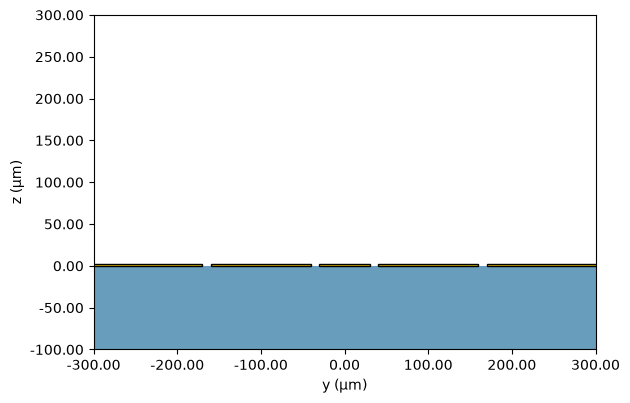

In [7]:
# Centre of each RF rail and inner edge of each outer ground along y (μm)
y_rf = center_width / 2 + gap + rf_width / 2
y_outer = center_width / 2 + 2 * gap + rf_width

# Half-width of the solver window and its height above the chip (μm)
half_width = 4000.0
top_height = 4000.0

# Width of each outer ground, reaching past the window edge (μm)
outer_width = half_width - y_outer + 100

# Cross-section of the five-wire trap
trap_spec = pf.PortSpec(
    description="Five-wire trap",
    width=2 * half_width,
    limits=(-substrate_thickness, top_height),
    num_modes=2,
    target_neff=1.5,
    path_profiles={
        "center": (center_width, 0, "METAL"),
        "rf0": (rf_width, y_rf, "METAL"),
        "rf1": (rf_width, -y_rf, "METAL"),
        "ground0": (outer_width, y_outer + outer_width / 2, "METAL"),
        "ground1": (outer_width, -y_outer - outer_width / 2, "METAL"),
    },
    voltage_path=[(y_outer, metal_thickness / 2), (y_rf, metal_thickness / 2)],
)

# Plot the cross-section around the trap
ax = pf.tidy3d_plot(trap_spec, frequency=f_rf)
ax.set_xlim(-300, 300)
ax.set_ylim(-100, 300)
ax.set_title("")
plt.show()

## RF field of the electrode cross-section

The port specification turns into a mode solver with `to_tidy3d`. Two settings are added before solving:

- **Mesh.** PhotonForge refines the mesh around the electrode edges and inside the gaps on its own. Away from the metal, it sizes cells from the wavelength, which here is metres long, so the region where the ion sits would get cells about 100 µm wide. A mesh override sets 1 µm cells over the region that holds the ion and its escape point.
- **Symmetry.** Both RF rails carry the same voltage, so the potential is mirror symmetric about $y = 0$ and only the half $y > 0$ is solved. The value `1` selects this symmetric case.

In [8]:
# Mode solver for the cross-section at the drive frequency
trap_solver = trap_spec.to_tidy3d([f_rf])

# Mesh the region of the ion and its escape point with 1 μm cells
ion_region = td.MeshOverrideStructure(
    geometry=td.Box.from_bounds((-1, -y_outer - 20, -10), (1, y_outer + 20, 300)),
    dl=(None, 1.0, 1.0),
)
grid_spec = trap_solver.simulation.grid_spec.updated_copy(
    override_structures=[ion_region]
)

# Solve only the half y > 0, using the mirror symmetry of the trap
simulation = trap_solver.simulation.updated_copy(
    symmetry=(0, 1, 0), grid_spec=grid_spec
)
trap_solver = trap_solver.updated_copy(simulation=simulation)

The left plot shows the whole solver window and its mesh: the cells are small near the electrodes and grow towards the window edges. The shaded half is the mirror image of the solved half. The right plot zooms into the gap between the central ground and an RF rail.

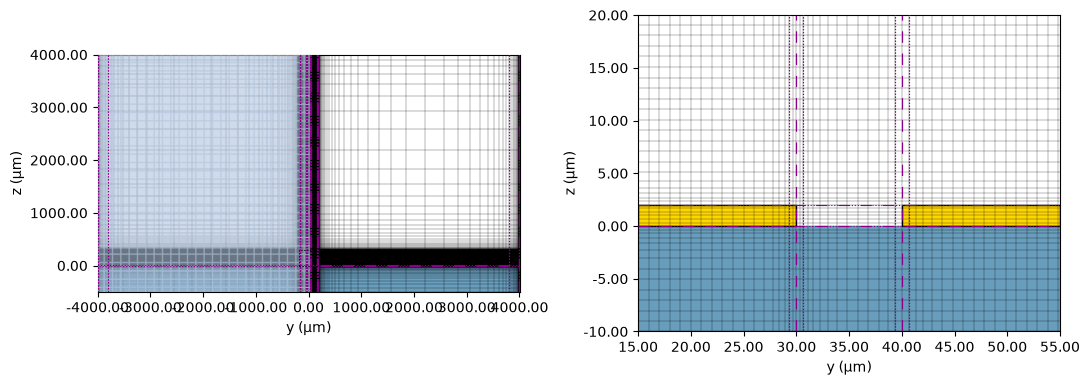

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4), tight_layout=True)

# Whole solver window with its mesh
simulation.plot(x=0, ax=ax[0])
simulation.plot_grid(x=0, ax=ax[0])

# Close-up of the gap between the central ground and an RF rail
y_gap = center_width / 2 + gap / 2
simulation.plot(
    x=0, ax=ax[1], hlim=(y_gap - 2 * gap, y_gap + 2 * gap), vlim=(-gap, 2 * gap)
)
simulation.plot_grid(
    x=0, ax=ax[1], hlim=(y_gap - 2 * gap, y_gap + 2 * gap), vlim=(-gap, 2 * gap)
)
for a in ax:
    a.set_title("")
plt.show()

The next cell sends the cross-section to the cloud and waits for the result, which takes about a minute. PhotonForge caches each result, so running the cell again with the same geometry and frequency costs nothing. Changing only `v_rf` never needs a new solve, because the voltage enters only through the pseudopotential formula.

In [10]:
# Solve for the two quasi-TEM modes of the electrode cross-section
trap_solver = pf.port_modes(trap_solver, task_name="Surface trap")

# Effective index of each mode
print("Effective indices:", trap_solver.data.n_eff.values.ravel())

Uploading task 'Surface trap…'Progress: 0% -
Starting task 'Surface trap': https://tidy3d.simulation.cloud/workbench?taskId=mo-4d33c147-e379-4128-9f2a-6c2ce232b299
Progress: 100% 
Effective indices: [1.5275017  1.50437076]


The solver finds two **quasi-TEM** modes, whose transverse electric field is the static field of the electrodes for a particular set of voltages. There are two because the half cross-section holds three conductors, the RF rail, the central ground and the outer ground, and only voltage differences between them matter. Their effective indices lie between 1 and 1.95, since part of each mode's field runs in the substrate.

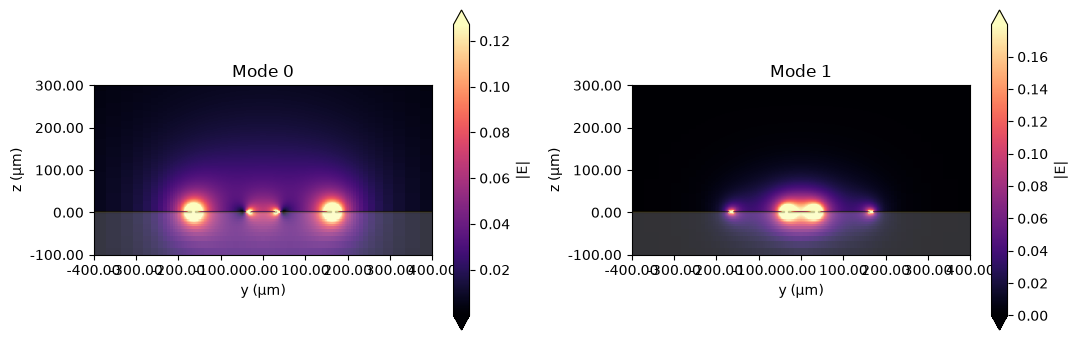

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5), tight_layout=True)

# Electric field magnitude of each mode around the trap
for m in range(2):
    trap_solver.plot_field("E", "abs", mode_index=m, f=f_rf, ax=ax[m])
    ax[m].set_xlim(-400, 400)
    ax[m].set_ylim(-100, 300)
    ax[m].set_title(f"Mode {m}")
plt.show()

## Field with the RF rails at 1 V

Neither mode is the field of the actual trap, where the RF rails are at $V_{RF}$ and both grounds are at 0 V. Each mode is a different mix of conductor voltages. Because the field depends linearly on the voltages, the trap field is a weighted sum of the two modes, $\mathbf{E} = c_0 \mathbf{E}_0 + c_1 \mathbf{E}_1$.

The weights come from the conductor voltages. Along a line at mid-height of the electrodes, starting inside the outer ground, the potential relative to the outer ground is

$$\phi(y) = -\int_{y_{outer}}^{y} E_y \, dy'.$$

Its value at the centre of the RF rail and at the centre of the central ground gives a $2 \times 2$ matrix $M$ of conductor voltages in each mode. Solving $M \mathbf{c} = (1, 0)$ gives the weights that put the RF rail at 1 V and the central ground at 0 V.

In [12]:
# Mode fields on the cross-section at the drive frequency
fields = {
    component: trap_solver.data.field_components[component].isel(f=0).squeeze(drop=True)
    for component in ("Ey", "Ez")
}

# Line at mid-height of the electrodes, from inside the outer ground to the centre (μm)
y_line = np.linspace(y_outer + gap / 2, 0, 4001)

# Potential along the line in each mode, relative to the outer ground (V)
potentials = [
    -cumulative_trapezoid(
        fields["Ey"].isel(mode_index=m).interp(y=y_line, z=metal_thickness / 2).values,
        y_line,
        initial=0,
    )
    for m in range(2)
]

# Voltage of the RF rail (first row) and of the central ground (second row) in each mode
voltages = np.array(
    [
        [np.interp(y_rf, y_line[::-1], phi[::-1]) for phi in potentials],
        [phi[-1] for phi in potentials],
    ]
)

# Mode weights that put the RF rail at 1 V and the central ground at 0 V
weights = np.linalg.solve(voltages, [1.0, 0.0])

# Field of the trap per volt on the RF rails (V/μm)
e_unit = {
    component: sum(weights[m] * fields[component].isel(mode_index=m) for m in range(2))
    for component in fields
}

## Pseudopotential and trap metrics

The field per volt is sampled on a regular 0.5 µm grid around the trap, scaled by $V_{RF}$ and converted to the pseudopotential. The cell then finds:

- the **ion position**, the minimum of $\Psi$ on the symmetry axis $y = 0$,
- the **trap depth**, the highest value of $\Psi$ on the axis above the ion (the saddle point),
- the **secular frequencies**, from parabolas fitted to $\Psi$ within 3 µm of the ion along $y$ and along $z$,
- the **Mathieu parameter** $q_M$, from the higher of the two secular frequencies.

In [13]:
# Regular sampling grid around the trap (μm)
y_grid = np.arange(-150, 150.01, 0.5)
z_grid = np.arange(metal_thickness + 1, 350, 0.5)

# Squared field magnitude per volt on the grid, shape (y, z), in (V/μm)²
e2_unit = sum(
    np.abs(e_unit[component].interp(y=y_grid, z=z_grid).values) ** 2
    for component in e_unit
)

# Pseudopotential in J; the factor 1e12 converts (V/μm)² to (V/m)²
omega_rf = 2 * np.pi * f_rf
psi = ion_charge**2 * v_rf**2 * e2_unit * 1e12 / (4 * ion_mass * omega_rf**2)

# Pseudopotential in meV
psi_mev = psi / elementary_charge * 1e3

In [15]:
# Pseudopotential along the symmetry axis y = 0
i_axis = np.argmin(np.abs(y_grid))
psi_axis = psi[i_axis, :]

# Ion position: minimum of the pseudopotential on the axis
i_ion = np.argmin(psi_axis)
z_ion = z_grid[i_ion]
ion_height = z_ion - metal_thickness

# Escape point: maximum of the pseudopotential above the ion
i_saddle = i_ion + np.argmax(psi_axis[i_ion:])
trap_depth = psi_mev[i_axis, i_saddle] - psi_mev[i_axis, i_ion]

# Points within 3 μm of the ion for the parabola fits
fit_range = 3.0
near_z = np.abs(z_grid - z_ion) <= fit_range
near_y = np.abs(y_grid) <= fit_range

# Curvature of the pseudopotential along z and y (J/μm²)
curvature_z = 2 * np.polyfit(z_grid[near_z] - z_ion, psi_axis[near_z], 2)[0]
curvature_y = 2 * np.polyfit(y_grid[near_y], psi[near_y, i_ion], 2)[0]

# Secular angular frequencies; the factor 1e12 converts 1/μm² to 1/m²
omega_z = np.sqrt(curvature_z * 1e12 / ion_mass)
omega_y = np.sqrt(curvature_y * 1e12 / ion_mass)

# Radial secular frequency (Hz) and Mathieu parameter
f_secular = min(omega_y, omega_z) / (2 * np.pi)
q_mathieu = 2 * np.sqrt(2) * max(omega_y, omega_z) / omega_rf

print(f"Ion height above the electrodes: {ion_height:.1f} μm")
print(f"Secular frequency, lateral: {omega_y / 2 / np.pi / 1e6:.2f} MHz")
print(f"Secular frequency, vertical: {omega_z / 2 / np.pi / 1e6:.2f} MHz")
print(f"Mathieu parameter q: {q_mathieu:.3f}")
print(f"Trap depth: {trap_depth:.1f} meV")

Ion height above the electrodes: 75.5 μm
Secular frequency, lateral: 3.54 MHz
Secular frequency, vertical: 3.56 MHz
Mathieu parameter q: 0.251
Trap depth: 47.7 meV


The map shows the pseudopotential above the electrodes, with the colour scale capped at twice the trap depth. The ion sits in the dark spot at the RF null. The saddle point above it marks where an ion with enough energy escapes.

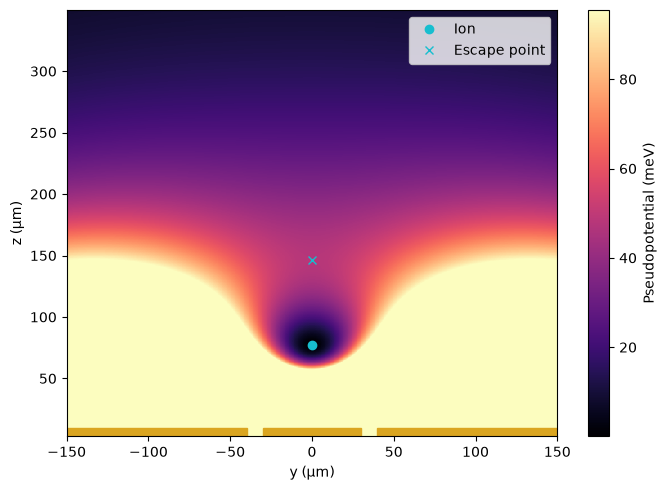

In [16]:
fig, ax = plt.subplots(figsize=(7, 5), tight_layout=True)

# Pseudopotential map in meV
mesh = ax.pcolormesh(
    y_grid, z_grid, psi_mev.T, vmax=2 * trap_depth, cmap="magma", shading="auto"
)
fig.colorbar(mesh, ax=ax, label="Pseudopotential (meV)")

# Ion position and escape point
ax.plot(0, z_ion, "o", color="tab:cyan", label="Ion")
ax.plot(0, z_grid[i_saddle], "x", color="tab:cyan", label="Escape point")

# Electrode positions along the bottom edge
for y0, y1 in [
    (-center_width / 2, center_width / 2),
    (center_width / 2 + gap, center_width / 2 + gap + rf_width),
    (-center_width / 2 - gap - rf_width, -center_width / 2 - gap),
]:
    ax.axvspan(y0, y1, ymax=0.02, color="goldenrod")
ax.set_xlabel("y (μm)")
ax.set_ylabel("z (μm)")
ax.set_xlim(y_grid[0], y_grid[-1])
ax.legend(loc="upper right")
plt.show()

## Score

The score function checks each constraint of the challenge. If all of them pass, the score is the trap depth in meV; otherwise it is zero. Ties on the leaderboard are broken by the lower RF voltage.

In [17]:
def trap_score(ion_height, f_secular, q_mathieu, v_rf, min_feature, trap_depth):
    # Pass or fail for every constraint of the challenge
    checks = {
        "Ion height 50 to 100 μm": 50 <= ion_height <= 100,
        "Radial secular frequency at least 1 MHz": f_secular >= 1e6,
        "Mathieu parameter q at most 0.4": q_mathieu <= 0.4,
        "Peak RF voltage at most 100 V": v_rf <= 100,
        "Minimum electrode feature or gap at least 5 μm": min_feature >= 5,
    }

    # Print the outcome of each check
    for name, passed in checks.items():
        print(f"{'PASS' if passed else 'FAIL'}  {name}")

    # Trap depth if every constraint passes, zero otherwise
    return trap_depth if all(checks.values()) else 0.0


# Smallest drawn feature or gap of the layout (μm)
min_feature = min(center_width, rf_width, gap)

# Score of the current design
score = trap_score(ion_height, f_secular, q_mathieu, v_rf, min_feature, trap_depth)
print(f"\nScore: {score:.1f} meV at {v_rf:.0f} V")

PASS  Ion height 50 to 100 μm
PASS  Radial secular frequency at least 1 MHz
PASS  Mathieu parameter q at most 0.4
PASS  Peak RF voltage at most 100 V
PASS  Minimum electrode feature or gap at least 5 μm

Score: 47.7 meV at 60 V


## Where to go from here

- **Voltage and frequency first.** Use the scaling laws in the primer: for a fixed geometry, $\Psi \propto V_{RF}^2/\Omega^2$ and $q_M \propto V_{RF}/\Omega^2$. Work out which combination of $V_{RF}$ and $f_{RF}$ gives the deepest trap while keeping $q_M \le 0.4$ and $V_{RF} \le 100$ V. Changing `v_rf` reuses the cached field.
- **Then the geometry.** The RF width and the gap set the ion height and how much field reaches the ion per volt. Use the height estimate to stay inside the 50 to 100 µm window, then compare the trap depth of a few geometries at their best voltage and frequency.
- **Sweeps.** To compare many designs, put the cells from the trap cross-section to the score into a loop over a list of parameters. Every new geometry or frequency costs one cross-section solve, so plan your sweeps with the compute budget in mind.